# Landmark observations — overlay

Each detection's landmark from `landmarks/<seq>/<backend>.npz`: a Gaussian over
the object's map-frame position. Green = a landmark was found, red = the bbox
enclosed no usable keypoint, so the detection carries none.

Per box: `·` the keypoints that produced the landmark, `×` any a filter
rejected — none when none is active. `+` the landmark centre reprojected,
and the ellipse its 1-sigma **extent** — the object's physical spread, not the
(much tighter) uncertainty about its centre.

Set `DATASET` below. On **MOrangeT** the dataset ships `oranges-3d.txt`, a 3D
centre and radius per fruit, drawn here as blue rings — so the overlay can be
read against ground truth rather than just inspected. On **LettuceMOTS** there
is no such file and the rings are absent.

Filters are taken from the `.npz`, not assumed. The depth filter shaves the
object's own near face (it cuts only along the viewing axis), so `×` marks
points that are mostly still the object. The green filter is lettuce-only —
excess green would discard an orange.

In [1]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Ellipse

ROOT = Path.cwd()
if ROOT.name == "lab":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts" / "landmarks"))

from mapsort.data import sequence
from sfm_mapping import read_dets, read_excess_green, read_keypoints, read_points3D, read_track_length

DATASET, SEQ, SPLIT, BACKEND = "moranget", "V01", "test", "sfm"
# DATASET, SEQ, SPLIT, BACKEND = "lettucemots", "0011", "test", "sfm"

seq = sequence(DATASET, SPLIT, SEQ)
root = ROOT / "data" / DATASET
model = root / "recon" / SEQ / "model_txt"

lm = dict(np.load(seq.landmark_path(BACKEND)))
keypoints = read_keypoints(model / "images.txt")
points3D = read_points3D(model / "points3D.txt")
frames, det_idx, boxes = read_dets(seq.dets_path)
images = {i + 1: p for i, p in enumerate(seq.image_paths())}
W, H = int(seq.info["imWidth"]), int(seq.info["imHeight"])

# SIMPLE_* and RADIAL carry one focal before the principal point; PINHOLE carries fx and fy.
cam = [l.split() for l in (model / "cameras.txt").read_text().splitlines() if not l.startswith("#")][0]
if cam[1] in ("PINHOLE", "OPENCV", "FULL_OPENCV"):
    fx, fy, cx, cy = (float(v) for v in cam[4:8])
else:
    fx = fy = float(cam[4])
    cx, cy = float(cam[5]), float(cam[6])

# MOrangeT ships a 3D centre and radius per fruit, row i for track id i+1.
gt3d_path = root / "raw" / SEQ / "oranges-3d.txt"
gt3d = np.loadtxt(gt3d_path, delimiter=",") if gt3d_path.exists() else None

assert len(frames) == len(lm["has_landmark"]), "landmarks and dets are out of step"
GREEN = float(lm["green"]) if "green" in lm else float("nan")  # what this file was generated with
MIN_TRACK = int(lm["min_track"]) if "min_track" in lm else 0
exg = read_excess_green(model / "points3D.txt") if np.isfinite(GREEN) else {}
track = read_track_length(model / "points3D.txt") if MIN_TRACK else {}
print(f"{DATASET}/{SEQ}: {len(frames)} dets, {lm['has_landmark'].sum()} with a landmark, "
      f"{W}x{H}, {cam[1]} f=({fx:.0f}, {fy:.0f})\n"
      f"  green filter {'off' if not np.isfinite(GREEN) else f'at {GREEN:g}'}, "
      f"min track {MIN_TRACK or 'off'}, "
      f"3D GT: {'none' if gt3d is None else f'{len(gt3d)} fruits'}\n"
      f"  keypoints per landmark: median {int(np.median(lm['n_kept'][lm['has_landmark']]))}")

moranget/V01: 7848 dets, 6037 with a landmark, 1083x1944, PINHOLE f=(1684, 1684)
  green filter off, min track 5, 3D GT: 110 fruits
  keypoints per landmark: median 2


## Overlay

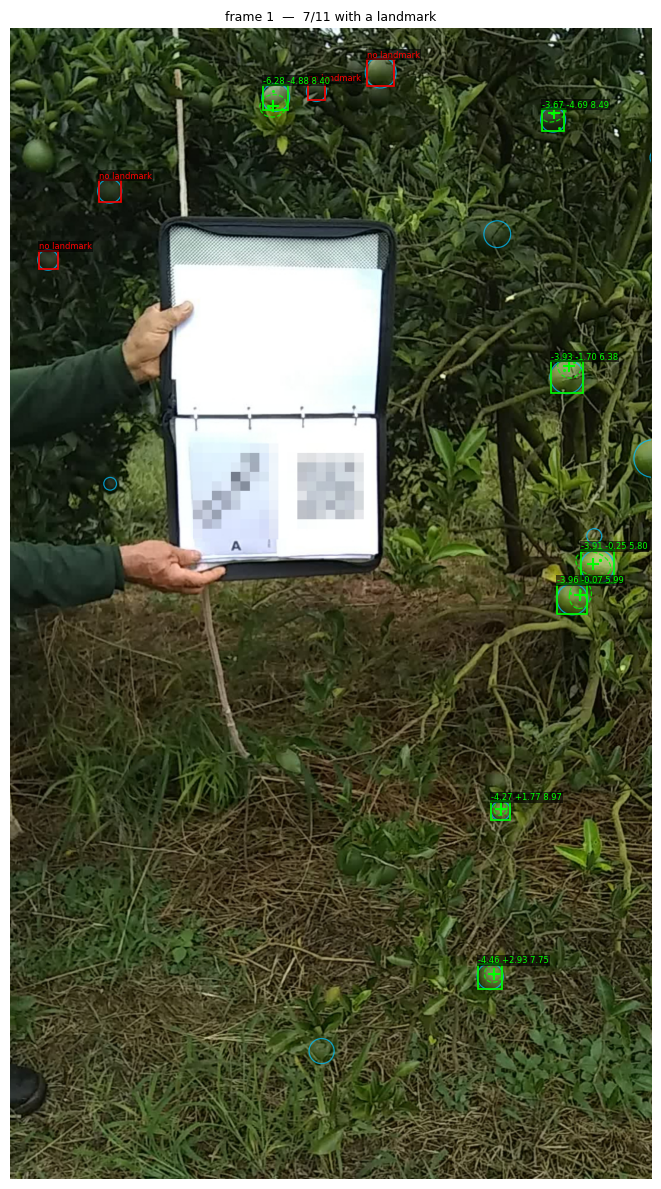

In [2]:
def project(X, R, t):
    """World points to pixels (radial distortion ignored)."""
    c = np.atleast_2d(X) @ R.T + t
    return np.column_stack([fx * c[:, 0] / c[:, 2] + cx, fy * c[:, 1] / c[:, 2] + cy]), c


def draw_gt3d(ax, R, t):
    """Shipped 3D fruits as rings at their true radius, where they fall in frame."""
    uv, c = project(gt3d[:, :3], R, t)
    vis = (c[:, 2] > 0) & (uv[:, 0] > -W) & (uv[:, 0] < 2 * W) & (uv[:, 1] > -H) & (uv[:, 1] < 2 * H)
    for (u, v), radius, z in zip(uv[vis], gt3d[vis, 3], c[vis, 2]):
        ax.add_patch(plt.Circle((u, v), fx * radius / z, fill=False, ec="deepskyblue", lw=0.9, alpha=0.75))


def overlay(frame_no, ax=None, fontsize=6, sigma=1.0, labels=True):
    if ax is None:
        _, ax = plt.subplots(figsize=(9 * W / H * 1.35, 12))
    ax.imshow(cv2.cvtColor(cv2.imread(str(images[frame_no])), cv2.COLOR_BGR2RGB))

    xy, ids, R, t = keypoints[images[frame_no].name]
    rows = np.flatnonzero(frames == frame_no)

    if gt3d is not None:
        draw_gt3d(ax, R, t)

    for i in rows:
        bbox, found = boxes[i], lm["has_landmark"][i]
        colour = "lime" if found else "red"
        x0, y0, x1, y1 = bbox
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=colour, lw=1.2))

        inside = np.all((xy >= bbox[:2]) & (xy <= bbox[2:]), axis=1)
        if inside.any():
            keep = (
                np.array([exg[j] for j in ids[inside]]) > GREEN
                if np.isfinite(GREEN)
                else np.ones(inside.sum(), dtype=bool)
            )
            if MIN_TRACK:
                keep &= np.array([track[j] >= MIN_TRACK for j in ids[inside]])
            ax.plot(*xy[inside][keep].T, ".", color=colour, ms=2.5, alpha=0.8)
            ax.plot(*xy[inside][~keep].T, "x", color="orange", ms=3, mew=0.8)

        if not found:
            if labels:
                ax.text(x0, max(y0 - 3, 8), "no landmark", color=colour, fontsize=fontsize,
                        bbox=dict(fc="black", alpha=0.6, pad=0.7, lw=0))
            continue

        p = lm["position"][i]
        uv, cam_pt = project(p, R, t)
        ax.plot(*uv[0], "+", color=colour, ms=9, mew=1.5)

        # First-order propagation of the world-frame extent into the image.
        x, y, z = cam_pt[0]
        J = np.array([[fx / z, 0, -fx * x / z**2], [0, fy / z, -fy * y / z**2]])
        C = J @ (R @ lm["extent"][i] @ R.T) @ J.T
        vals, vecs = np.linalg.eigh(C)
        vals = np.clip(vals, 0, None)
        ax.add_patch(Ellipse(uv[0], *(2 * sigma * np.sqrt(vals)),
                             angle=np.degrees(np.arctan2(*vecs[::-1, 1])),
                             fill=False, ec=colour, lw=0.9, ls="--", alpha=0.8))

        if labels:
            ax.text(x0, max(y0 - 3, 8), f"{p[0]:+.2f} {p[1]:+.2f} {p[2]:.2f}", color=colour,
                    fontsize=fontsize, bbox=dict(fc="black", alpha=0.6, pad=0.7, lw=0))

    found = int(lm["has_landmark"][rows].sum())
    ax.set(xlim=(0, W), ylim=(H, 0))
    ax.set_title(f"frame {frame_no}  —  {found}/{len(rows)} with a landmark", fontsize=9)
    ax.axis("off")
    return ax


overlay(1)
plt.tight_layout()

Frames with the most missing landmarks — where the method fails.

worst frames: [112, 315, 316, 323, 328, 322, 327, 252]


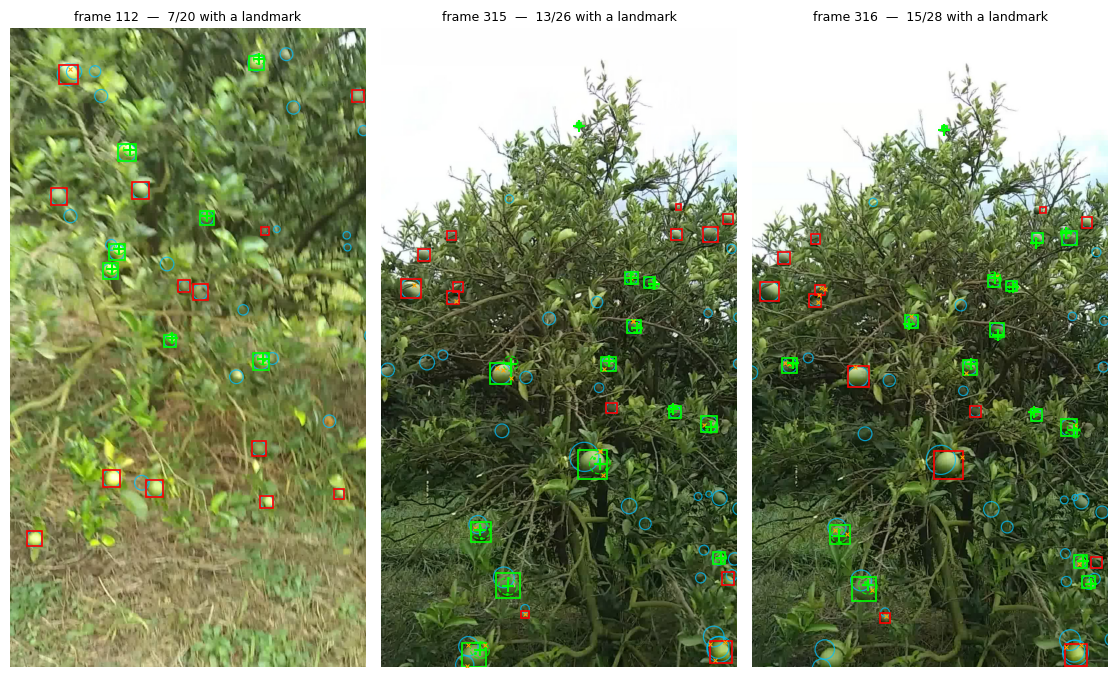

In [3]:
per_frame = {f: np.flatnonzero(frames == f) for f in np.unique(frames)}
worst = sorted(per_frame, key=lambda f: -int((~lm["has_landmark"][per_frame[f]]).sum()))
print("worst frames:", worst[:8])

fig, axes = plt.subplots(1, 3, figsize=(5 * 3 * W / H * 1.35, 9))
for ax, frame_no in zip(axes, worst[:3]):
    overlay(frame_no, ax=ax, labels=False)
plt.tight_layout()

## Extent is not uncertainty

`extent` is the object's physical spread and stays put; `covariance` is the
uncertainty about its centre and shrinks as `extent / n_kept`. Fusing the wrong
one across observations would claim precision finer than the object itself.

On MOrangeT the divisor is barely doing anything honest: the median box
encloses only a couple of triangulated keypoints that survive `--min-track`, so
`n_kept` is small and `extent` itself is estimated from too few points to be a
shape at all.

ratio extent/centre: 1.3 x


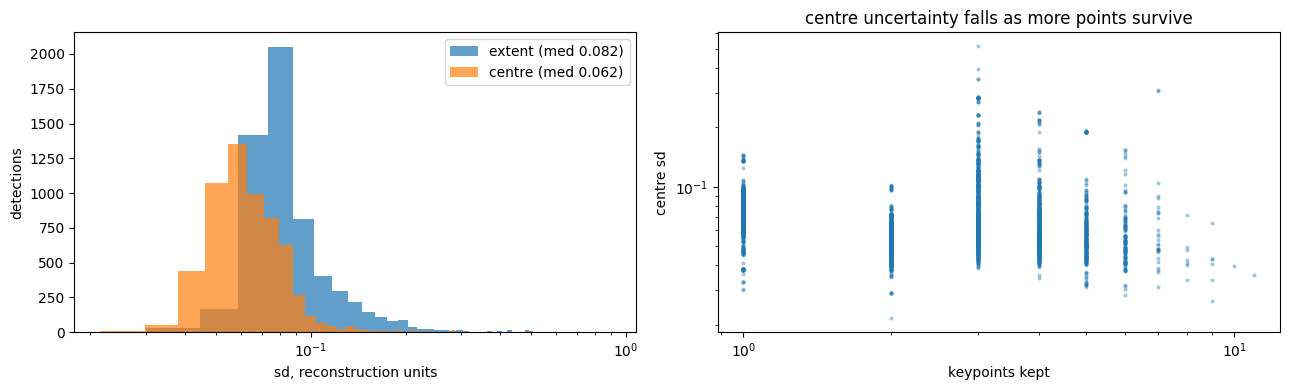

In [4]:
h = lm["has_landmark"]
sd_ext = np.sqrt(np.array([np.diag(e) for e in lm["extent"][h]]))
sd_cov = np.sqrt(np.array([np.diag(c) for c in lm["covariance"][h]]))

fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4))
a.hist(sd_ext.mean(1), bins=60, alpha=0.7, label=f"extent (med {np.median(sd_ext):.3f})")
a.hist(sd_cov.mean(1), bins=60, alpha=0.7, label=f"centre (med {np.median(sd_cov):.3f})")
a.set(xlabel="sd, reconstruction units", ylabel="detections", xscale="log")
a.legend()

b.scatter(lm["n_kept"][h], sd_cov.mean(1), s=4, alpha=0.3)
b.set(xlabel="keypoints kept", ylabel="centre sd", xscale="log", yscale="log",
      title="centre uncertainty falls as more points survive")
plt.tight_layout()
print("ratio extent/centre:", round(float(np.median(sd_ext) / np.median(sd_cov)), 1), "x")

## The map

Top-down `XY` coloured by frame, with the shipped 3D fruits in black where the
dataset has them. On MOrangeT the camera walks one tree face, so the landmarks
should trace a canopy rather than two rows, and should sit on the black points.

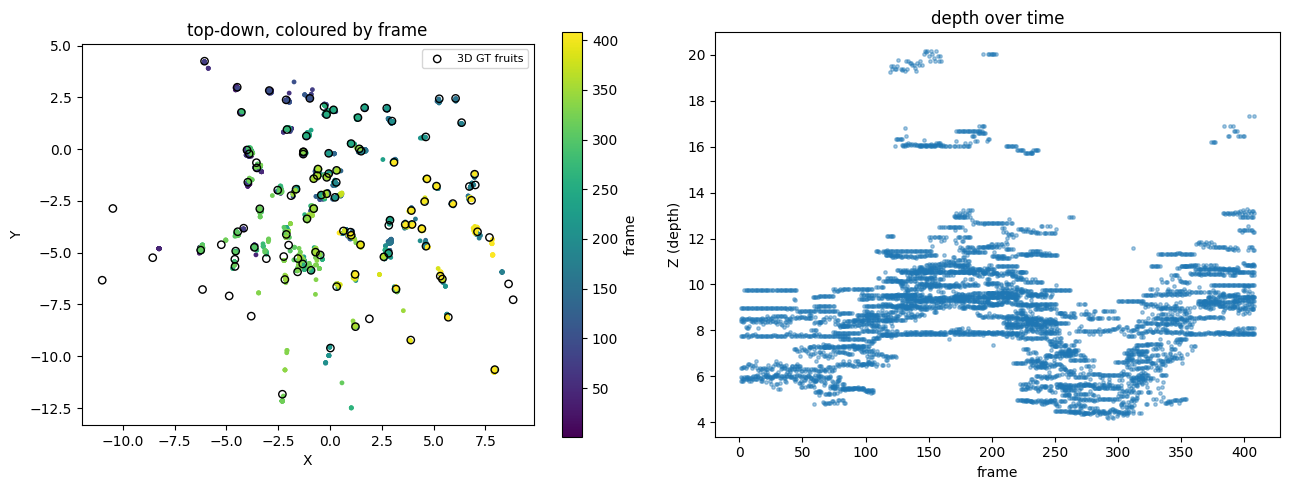

In [5]:
pos, fr = lm["position"][h], lm["frame"][h]

fig, (a, b) = plt.subplots(1, 2, figsize=(13, 5))
s = a.scatter(pos[:, 0], pos[:, 1], c=fr, s=6, cmap="viridis")
if gt3d is not None:
    a.scatter(gt3d[:, 0], gt3d[:, 1], s=28, fc="none", ec="black", lw=1.0, label="3D GT fruits")
    a.legend(loc="best", fontsize=8)
a.set(xlabel="X", ylabel="Y", title="top-down, coloured by frame")
a.set_aspect("equal")
fig.colorbar(s, ax=a, label="frame")

b.scatter(fr, pos[:, 2], s=6, alpha=0.4)
b.set(xlabel="frame", ylabel="Z (depth)", title="depth over time")
plt.tight_layout()

## How far off are they? (MOrangeT only)

`oranges-3d.txt` gives a true 3D centre per fruit, and its row `i` is track id
`i+1` — confirmed below, since the distance to the *same-index* fruit matches
the distance to the *nearest* fruit of any index. That makes this an actual
mapping-accuracy number rather than a consistency check: per track, the median
landmark position against its own fruit, in units of fruit radii.

The GT ids come from `gt.txt`, which is row-aligned with `dets/<seq>.txt` and
so with the `.npz` — `gt_to_dets.py` copies it line by line.

Note this is the *fused* error, a median over all of a fruit's observations;
a single observation is much worse. It is also an upper bound on what the
tracker sees, since it uses GT association to decide which rows belong together.

104/110 fruits localised; median GT radius 0.113, errors in radii
  to its own fruit:  median 0.93  p90 4.11
  to nearest fruit:  median 0.92   (matching this is what confirms the id mapping)
  tail: 7 fruits worse than 5 radii
  error vs observations: Spearman -0.47 (p=4e-07); <20 obs 3.51 vs >=20 obs 0.89


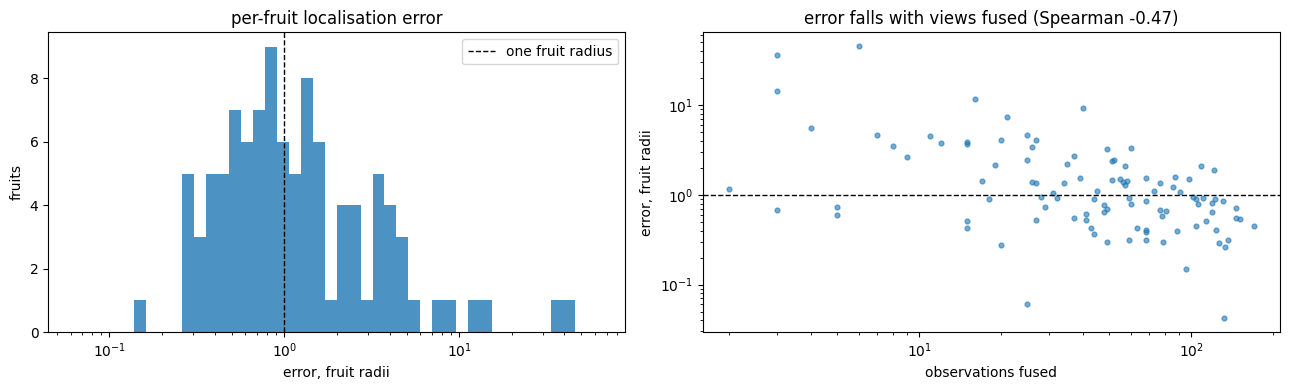

In [6]:
if gt3d is None:
    print(f"{DATASET} ships no 3D ground truth; nothing to score against")
else:
    from scipy.stats import spearmanr

    track_ids = seq.gt_rows()[:, 1].astype(int)
    assert len(track_ids) == len(frames), "gt.txt and dets are out of step"
    radius = np.median(gt3d[:, 3])

    own, nearest, counts = [], [], []
    for tid in range(1, len(gt3d) + 1):
        m = (track_ids == tid) & lm["has_landmark"]
        if not m.any():
            continue
        est = np.median(lm["position"][m], axis=0)
        own.append(np.linalg.norm(est - gt3d[tid - 1, :3]))
        nearest.append(np.linalg.norm(gt3d[:, :3] - est, axis=1).min())
        counts.append(m.sum())
    own, nearest, counts = np.array(own) / radius, np.array(nearest) / radius, np.array(counts)
    rho, pval = spearmanr(counts, own)

    print(f"{len(own)}/{len(gt3d)} fruits localised; median GT radius {radius:.3f}, errors in radii")
    print(f"  to its own fruit:  median {np.median(own):.2f}  p90 {np.percentile(own, 90):.2f}")
    print(f"  to nearest fruit:  median {np.median(nearest):.2f}"
          f"   (matching this is what confirms the id mapping)")
    print(f"  tail: {(own > 5).sum()} fruits worse than 5 radii")
    print(f"  error vs observations: Spearman {rho:+.2f} (p={pval:.0e});"
          f" <20 obs {np.median(own[counts < 20]):.2f} vs >=20 obs {np.median(own[counts >= 20]):.2f}")

    fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4))
    a.hist(own, bins=np.logspace(-1.2, 1.8, 45), alpha=0.8)
    a.axvline(1, color="black", ls="--", lw=1, label="one fruit radius")
    a.set(xlabel="error, fruit radii", ylabel="fruits", xscale="log",
          title="per-fruit localisation error")
    a.legend()

    b.scatter(counts, own, s=12, alpha=0.6)
    b.axhline(1, color="black", ls="--", lw=1)
    b.set(xlabel="observations fused", ylabel="error, fruit radii", xscale="log", yscale="log",
          title=f"error falls with views fused (Spearman {rho:+.2f})")
    plt.tight_layout()